# Developing the app with Gradio

In [1]:
# If already have env
!pip install gradio 
# !pip install -r requirements.txt

  Using cached aiofiles-23.2.1-py3-none-any.whl.metadata (9.7 kB)
  Using cached ffmpy-0.4.0-py3-none-any.whl.metadata (2.9 kB)
  Using cached httpx-0.27.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached MarkupSafe-2.1.5-cp39-cp39-win_amd64.whl.metadata (3.1 kB)
  Using cached pillow-10.4.0-cp39-cp39-win_amd64.whl.metadata (9.3 kB)
  Using cached pydub-0.25.1-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached PyYAML-6.0.2-cp39-cp39-win_amd64.whl.metadata (2.1 kB)
  Using cached semantic_version-2.10.0-py2.py3-none-any.whl.metadata (9.7 kB)
  Using cached tomlkit-0.12.0-py3-none-any.whl.metadata (2.7 kB)
  Using cached typer-0.12.5-py3-none-any.whl.metadata (15 kB)
  Using cached websockets-12.0-cp39-cp39-win_amd64.whl.metadata (6.8 kB)
  Using cached httpcore-1.0.6-py3-none-any.whl.metadata (21 kB)
  Using cached shellingham-1.5.4-py2.py3-none-any.whl.metadata (3.5 kB)
  Using cached rich-13.9.2-py3-none-any.whl.metadata (18 kB)
  Using cached markdown_it_py-3.0.0-py3-none-any.whl

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
keras-nightly 3.0.4.dev2024013003 requires absl-py, which is not installed.
keras-nightly 3.0.4.dev2024013003 requires dm-tree, which is not installed.
keras-nightly 3.0.4.dev2024013003 requires h5py, which is not installed.
keras-nightly 3.0.4.dev2024013003 requires ml-dtypes, which is not installed.
keras-nightly 3.0.4.dev2024013003 requires namex, which is not installed.
tf-nightly-intel 2.16.0.dev20240129 requires absl-py>=1.0.0, which is not installed.
tf-nightly-intel 2.16.0.dev20240129 requires astunparse>=1.6.0, which is not installed.
tf-nightly-intel 2.16.0.dev20240129 requires flatbuffers>=23.5.26, which is not installed.
tf-nightly-intel 2.16.0.dev20240129 requires gast!=0.5.0,!=0.5.1,!=0.5.2,>=0.2.1, which is not installed.
tf-nightly-intel 2.16.0.dev20240129 requires google-pasta>=0.1.1, which is not

In [2]:
# load the dataset from pycaret
from pycaret.datasets import get_data
data = get_data('insurance')

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# initialize setup
from pycaret.regression  import *
s = setup(data, target = 'charges',
            session_id = 123,
            verbose = True)

,Description,Value
0,Session id,123
1,Target,charges
2,Target type,Regression
3,Original data shape,"(1338, 7)"
4,Transformed data shape,"(1338, 10)"
5,Transformed train set shape,"(936, 10)"
6,Transformed test set shape,"(402, 10)"
7,Numeric features,3
8,Categorical features,3
9,Preprocess,True


In [7]:
# train model
best = compare_models()

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
gbr,Gradient Boosting Regressor,2701.9927,23548981.3626,4832.9682,0.8320,0.4447,0.3137,0.0640
rf,Random Forest Regressor,2771.4583,25416502.3827,5028.6343,0.8172,0.4690,0.3303,0.1310
lightgbm,Light Gradient Boosting Machine,2992.1828,25521038.3331,5042.0978,0.8149,0.5378,0.3751,0.0770
et,Extra Trees Regressor,2833.3624,28427844.2412,5305.6516,0.7991,0.4877,0.3363,0.0990
ada,AdaBoost Regressor,4316.0568,29220505.6498,5398.4561,0.7903,0.6368,0.7394,0.0380
lar,Least Angle Regression,4303.5559,38388058.4578,6176.5920,0.7306,0.5949,0.4433,0.0350
llar,Lasso Least Angle Regression,4303.7694,38386824.2786,6176.4846,0.7306,0.5952,0.4434,0.0300
br,Bayesian Ridge,4311.2349,38391950.0874,6176.8896,0.7306,0.5910,0.4447,0.0330
ridge,Ridge Regression,4317.6984,38396435.9578,6177.2329,0.7306,0.5891,0.4459,0.0390
lasso,Lasso Regression,4303.7697,38386797.6709,6176.4824,0.7306,0.5952,0.4434,0.0340


In [8]:
best

GradientBoostingRegressor(random_state=123)

### 

In [33]:
import pandas as pd
def predict_charges(age, bmi,sex,smoker,region,children):
    df = pd.DataFrame.from_dict({'sex': [sex], 'age': [age], 'smoker': [smoker],'bmi':[bmi],'region':[region],'children':[children]})
    
    pred = predict_model(best, df)['prediction_label'][0]
    
    #df = encode_attributes(df)
    #pred = blend_saved.predict(df).tolist()[0]
    return 'Cargos sanitarios : '+ str(round(pred,2))

In [34]:
import gradio as gr

sex = gr.Radio(['female', 'male'], label='sex')
smoker = gr.Radio(['no', 'yes'], label='smoker')
children = gr.Radio([2, 3, 1, 4, 5, 0], label='children')
region = gr.Radio(['northeast', 'southeast', 'northwest', 'southwest'], 
                         label='region')

age = gr.Slider(15, 75, value=16, label="Age", info="Choose between 15 and 75")
bmi = gr.Slider(15, 60, value=16, label="BMI", info="Choose between 15 and 60")

In [36]:
gr.Interface(predict_charges, inputs=[age, bmi,sex,smoker,region,children], 
             outputs='label',
             title='Medical Insurance Cost Prediction').launch()

Running on local URL:  http://127.0.0.1:7866

To create a public link, set `share=True` in `launch()`.


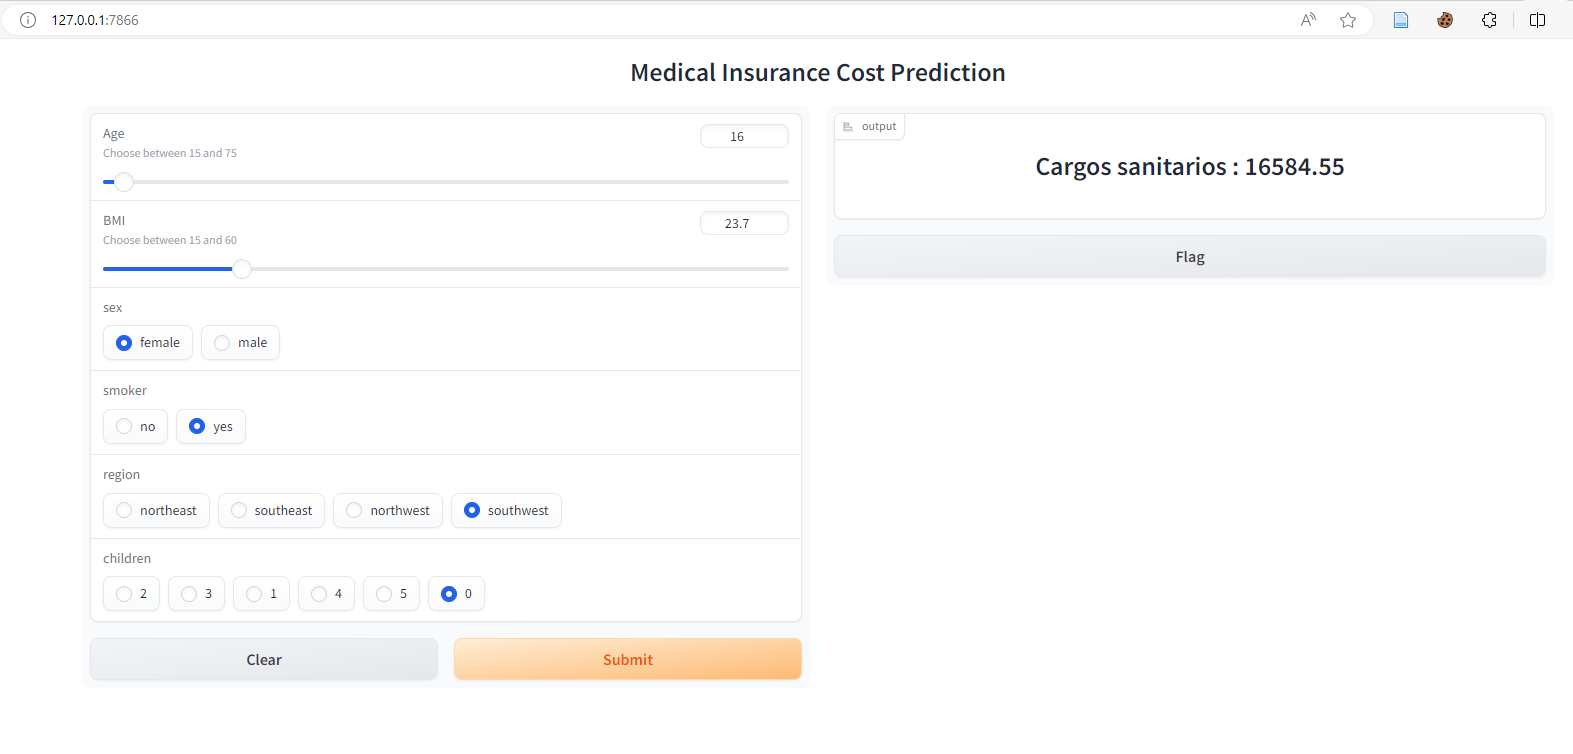